# Logistic Regression — Synthetic Email Generation (Steps 12E and 12F)

In this notebook, I generate controlled versions of legitimate emails that the baseline model previously classified as phishing. I use the counterfactual feature mappings from Notebook 04 to guide the edits. I first test a simple editing method (Step 12E), then refine the edits to make the text more natural (Step 12F).

I keep the trained Logistic Regression model and TF-IDF vectorizer unchanged. **I do not retrain the model or add the generated emails to the training set here.** The figures and summary tables below show the *recorded results* from the original experiment. Running the code is needed to check whether the same results can be reproduced.


### Recorded input summary

**Table 5.1 — Counterfactual templates available for generation**

| Input group | Number |
|:--|--:|
| Feasible counterfactual templates | 56 |
| Fully mapped templates used for generation | 52 |
| Templates set aside because mapping was incomplete | 4 |

The 52 fully mapped templates provide the starting emails for both editing stages. The other four are not used.


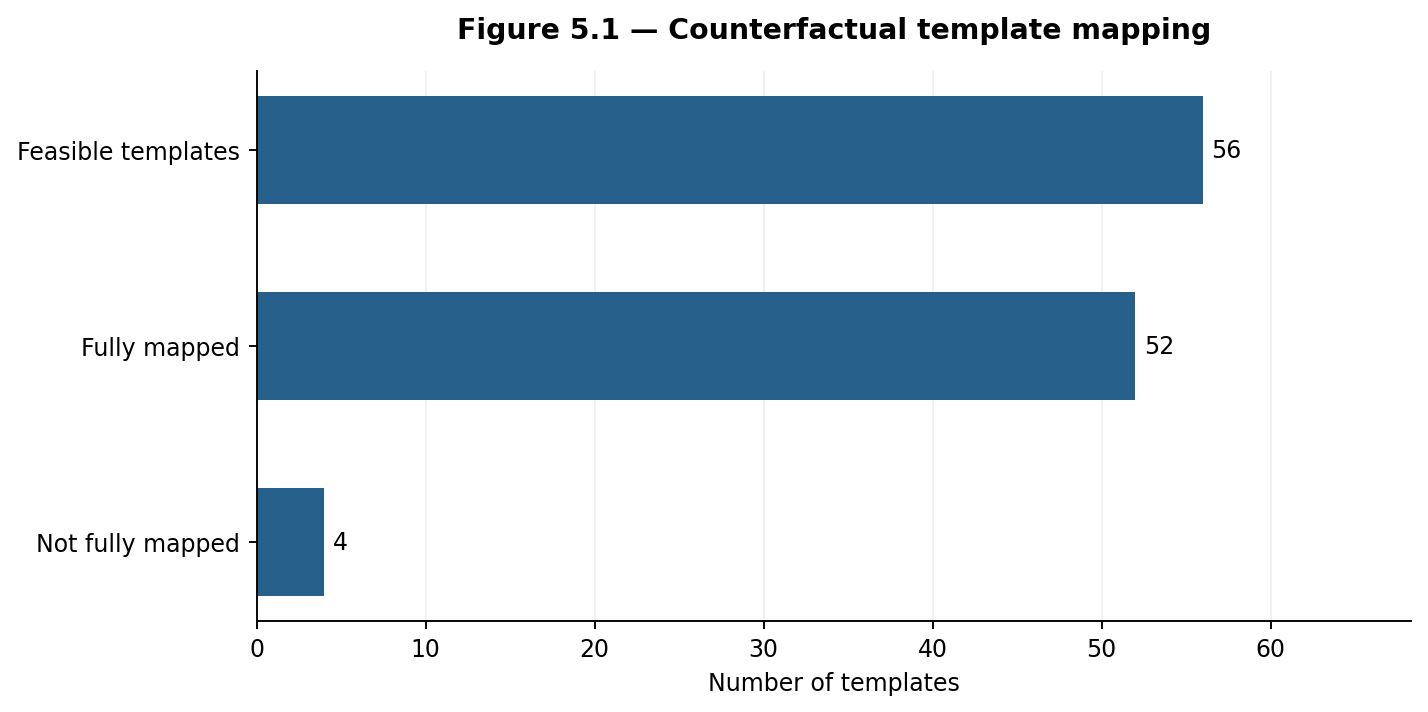

## 1. Inputs and experimental checks

The analysis requires the original baseline model, its fitted vectorizer, and the feature-to-text mappings from the counterfactual analysis. The checks below confirm that 56 feasible templates are available and that 52 have complete textual mappings. Four templates with unmatched features are excluded from generation.

In [ ]:
import os
import re
import json
import hashlib
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Resolve the baseline aliases used by the preceding notebooks.
if "lr_model" not in globals() and "lr_model_cf" in globals():
    lr_model = lr_model_cf

if "tfidf_vectorizer" not in globals() and "tfidf_vectorizer_cf" in globals():
    tfidf_vectorizer = tfidf_vectorizer_cf

required_objects = [
    "counterfactual_synthetic_templates_12d",
    "counterfactual_text_mapping_12d",
    "tfidf_vectorizer",
    "lr_model",
]

missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(
        "Required objects are missing: "
        + str(missing)
        + ". Run the verified notebooks through 04_counterfactual_analysis.ipynb first."
    )

assert len(counterfactual_synthetic_templates_12d) == 56
assert int((counterfactual_synthetic_templates_12d["Unmatched_Feature_Count"] == 0).sum()) == 52

print("Previous counterfactual objects verified.")
print("Feasible templates:", len(counterfactual_synthetic_templates_12d))
print("Fully mapped templates:", int((counterfactual_synthetic_templates_12d["Unmatched_Feature_Count"] == 0).sum()))

## 2. Controlled synthetic email generation (Step 12E)

For each fully mapped template, selected feature occurrences are replaced or removed in the source legitimate email. The edited text is compared with the original using Term Frequency-Inverse Document Frequency cosine similarity, and the baseline model is used to record its classification. The synthetic label remains legitimate (class 0).

This first editing procedure is retained as an intermediate experiment because some substitutions of domain-related tokens produce awkward wording. The subsequent refinement addresses that limitation.

In [ ]:
templates_12e = counterfactual_synthetic_templates_12d.copy()
mapping_12e = counterfactual_text_mapping_12d.copy()

clean_templates_12e = (
    templates_12e[templates_12e["Unmatched_Feature_Count"] == 0]
    .copy()
    .reset_index(drop=True)
)
reserved_templates_12e = (
    templates_12e[templates_12e["Unmatched_Feature_Count"] > 0]
    .copy()
    .reset_index(drop=True)
)

assert len(clean_templates_12e) == 52
assert len(reserved_templates_12e) == 4

SYNTHETIC_LABEL_12E = 0
BASELINE_THRESHOLD_12E = 0.50
MIN_LENGTH_RATIO_12E = 0.70
MAX_LENGTH_RATIO_12E = 1.10
MIN_TFIDF_SIMILARITY_12E = 0.80

NEUTRAL_REPLACEMENTS_12E = {
    "com":"website", "net":"network", "http":"website", "www":"website",
    "online":"digital", "account":"profile", "info":"details",
    "products":"items", "dear":"hello", "receive":"get", "site":"website",
    "computer":"device", "company":"organization", "contact":"reach",
    "page":"section", "link":"reference", "money":"funds", "buy":"purchase",
    "enter":"provide", "address":"location", "great":"useful",
    "paper":"document", "hours":"time", "wish":"would like"
}

def clean_text_12e(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def feature_regex_12e(feature):
    return r"(?<!\w)" + re.escape(str(feature).strip()) + r"(?!\w)"

def choose_occurrences_12e(total, number):
    if number <= 0:
        return []
    if number >= total:
        return list(range(total))
    return sorted(set(np.linspace(0, total - 1, num=number, dtype=int).tolist()))

def apply_feature_12e(text, feature, fraction_removed, fully_removed):
    pattern = feature_regex_12e(feature)
    matches = list(re.finditer(pattern, text, flags=re.IGNORECASE))
    n = len(matches)
    if n == 0:
        return text, 0, 0

    if fully_removed:
        number_to_change = n
    else:
        # Reconstructed preliminary editing rule; verify against original Step 12E source before treating as exact.
        number_to_change = max(1, int(round(n * float(fraction_removed))))
        number_to_change = min(n, number_to_change)

    selected = set(choose_occurrences_12e(n, number_to_change))
    replacement = NEUTRAL_REPLACEMENTS_12E.get(str(feature).lower().strip(), "")

    parts, previous_end, changed = [], 0, 0
    for i, match in enumerate(matches):
        parts.append(text[previous_end:match.start()])
        if i in selected:
            parts.append(replacement)
            changed += 1
        else:
            parts.append(text[match.start():match.end()])
        previous_end = match.end()
    parts.append(text[previous_end:])
    return clean_text_12e("".join(parts)), n, changed

In [ ]:
synthetic_records_12e = []
change_records_12e = []

for synthetic_id, template in enumerate(clean_templates_12e.itertuples(index=False), start=1):
    fp_number = int(template.FP_Number)
    original_text = clean_text_12e(template.Original_Email_Text)
    synthetic_text = original_text

    fp_mapping = (
        mapping_12e[mapping_12e["FP_Number"] == fp_number][
            ["Counterfactual_Feature_Rank", "Feature", "Fraction_Removed", "Fully_Removed"]
        ]
        .drop_duplicates(subset=["Counterfactual_Feature_Rank", "Feature"])
        .sort_values("Counterfactual_Feature_Rank")
        .reset_index(drop=True)
    )

    changed_features = []
    for _, row in fp_mapping.iterrows():
        synthetic_text, occurrences, changed = apply_feature_12e(
            synthetic_text,
            str(row["Feature"]),
            float(row["Fraction_Removed"]),
            bool(row["Fully_Removed"]),
        )
        if changed > 0:
            changed_features.append(str(row["Feature"]))
        change_records_12e.append({
            "Synthetic_ID": synthetic_id,
            "Source_FP_Number": fp_number,
            "Feature": str(row["Feature"]),
            "Original_Occurrences": occurrences,
            "Modified_Occurrences": changed,
        })

    original_length = len(original_text)
    synthetic_length = len(synthetic_text)
    synthetic_records_12e.append({
        "Synthetic_ID": synthetic_id,
        "Source_FP_Number": fp_number,
        "label": SYNTHETIC_LABEL_12E,
        "Original_Text": original_text,
        "Synthetic_Text": synthetic_text,
        "Counterfactual_Feature_Count": len(fp_mapping),
        "Applied_Feature_Change_Count": len(changed_features),
        "Changed_Features": " | ".join(changed_features),
        "Original_Length": original_length,
        "Synthetic_Length": synthetic_length,
        "Length_Ratio": synthetic_length / original_length if original_length else np.nan,
        "Text_Changed": original_text != synthetic_text,
    })

synthetic_all_12e = pd.DataFrame(synthetic_records_12e)
synthetic_change_log_12e = pd.DataFrame(change_records_12e)

assert len(synthetic_all_12e) == 52
assert int(synthetic_all_12e["Text_Changed"].sum()) == 52

original_matrix_12e = tfidf_vectorizer.transform(synthetic_all_12e["Original_Text"])
synthetic_matrix_12e = tfidf_vectorizer.transform(synthetic_all_12e["Synthetic_Text"])

similarities_12e = [
    float(cosine_similarity(original_matrix_12e[i], synthetic_matrix_12e[i])[0, 0])
    for i in range(len(synthetic_all_12e))
]
synthetic_all_12e["TFIDF_Cosine_Similarity"] = similarities_12e

prob_12e = lr_model.predict_proba(synthetic_matrix_12e)[:, 1]
pred_12e = (prob_12e >= BASELINE_THRESHOLD_12E).astype(int)
synthetic_all_12e["Baseline_Model_Phishing_Probability"] = prob_12e
synthetic_all_12e["Baseline_Model_Prediction"] = pred_12e

synthetic_all_12e["Generation_Quality_Pass"] = (
    synthetic_all_12e["Text_Changed"]
    & synthetic_all_12e["Length_Ratio"].between(MIN_LENGTH_RATIO_12E, MAX_LENGTH_RATIO_12E)
    & (synthetic_all_12e["TFIDF_Cosine_Similarity"] >= MIN_TFIDF_SIMILARITY_12E)
)

approved_synthetic_12e = (
    synthetic_all_12e[synthetic_all_12e["Generation_Quality_Pass"]]
    .drop_duplicates(subset=["Synthetic_Text"])
    .copy()
    .reset_index(drop=True)
)

# Locked Step 12E checkpoints from the executed experiment.
print("Step 12E quality passes (reconstructed):", int(synthetic_all_12e["Generation_Quality_Pass"].sum()))
print("Step 12E baseline legitimate predictions (reconstructed):", int((synthetic_all_12e["Baseline_Model_Prediction"] == 0).sum()))
print("Step 12E approved (reconstructed):", len(approved_synthetic_12e))
assert int(approved_synthetic_12e["Synthetic_Text"].duplicated().sum()) == 0

observed_12e = {
    "generated": len(synthetic_all_12e),
    "quality_passes": int(synthetic_all_12e["Generation_Quality_Pass"].sum()),
    "baseline_legitimate": int((synthetic_all_12e["Baseline_Model_Prediction"] == 0).sum()),
    "approved_nonduplicate": len(approved_synthetic_12e),
    "cosine_min": float(synthetic_all_12e["TFIDF_Cosine_Similarity"].min()),
    "cosine_max": float(synthetic_all_12e["TFIDF_Cosine_Similarity"].max()),
    "cosine_mean": float(synthetic_all_12e["TFIDF_Cosine_Similarity"].mean()),
    "cosine_median": float(synthetic_all_12e["TFIDF_Cosine_Similarity"].median()),
}
display(pd.DataFrame([observed_12e]).round(6))

### Step 12E — Recorded results

**Table 5.2 — Results of the first editing stage**

| Measure | Recorded result |
|:--|--:|
| Generated variants | 52 |
| Passed the generation-quality checks | 34 |
| Approved, non-duplicate variants | 34 |
| Predicted as legitimate by the unchanged baseline model | 30 |
| Minimum TF-IDF cosine similarity | 0.488909 |
| Maximum TF-IDF cosine similarity | 0.999326 |
| Mean TF-IDF cosine similarity | 0.859137 |
| Median TF-IDF cosine similarity | 0.918383 |

I approved 34 of the 52 generated variants in this first stage. The baseline model classified 30 variants as legitimate, but that number is **not the same as** the number that passed the quality checks. Some edits to web addresses and domain fragments sounded unnatural, so I refined the editing rules in Step 12F.


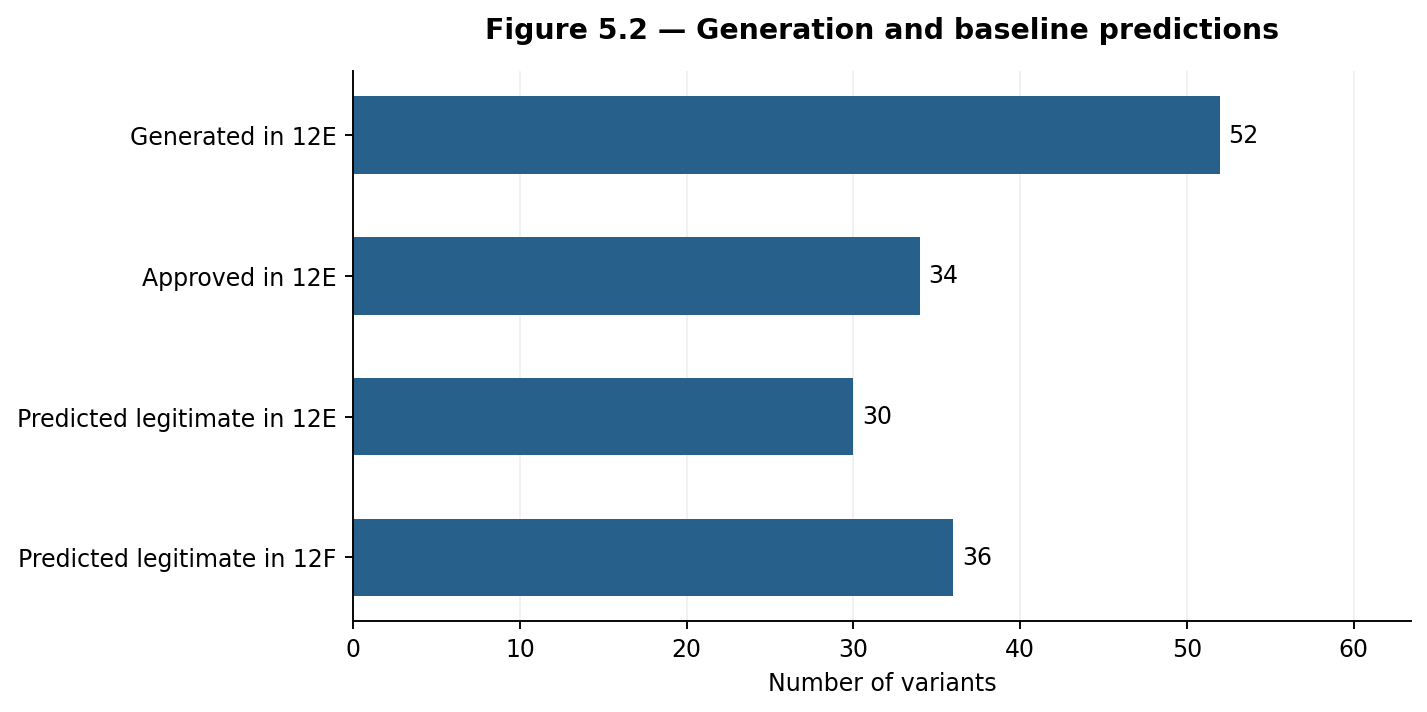

Figure 5.2 compares different checks. The 34 approved variants and the 30 or 36 legitimate predictions are **not mutually exclusive categories**, so their counts should not be added together. The figure uses the recorded results rather than a new model run.


## 3. Context-aware refinement and quality assessment (Step 12F)

The refined variants are created again from the **original email texts**, not from the preliminary edited texts. Domain and URL fragments, encoding artifacts, and ordinary words are treated differently to avoid unnatural substitutions.

A variant is accepted only when the text has changed, the requested counterfactual edits are sufficiently satisfied, the similarity and length requirements are met, and the resulting text is not duplicated. The thresholds and deterministic editing rules below are those used in the original refinement stage.

In [ ]:
EXPECTED_FEASIBLE_TEMPLATES_12F = 56
EXPECTED_FULLY_MAPPED_TEMPLATES_12F = 52
SYNTHETIC_LABEL_12F = 0
BASELINE_THRESHOLD_12F = 0.50

MIN_TFIDF_SIMILARITY_12F = 0.85
MIN_LENGTH_RATIO_12F = 0.80
MAX_LENGTH_RATIO_12F = 1.08
MIN_TOKEN_RETENTION_12F = 0.80
REDUCTION_TOLERANCE_12F = 0.10

templates_12f = counterfactual_synthetic_templates_12d.copy()
mapping_12f = counterfactual_text_mapping_12d.copy()

clean_templates_12f = (
    templates_12f[templates_12f["Unmatched_Feature_Count"] == 0]
    .copy().reset_index(drop=True)
)
reserved_templates_12f = (
    templates_12f[templates_12f["Unmatched_Feature_Count"] > 0]
    .copy().reset_index(drop=True)
)

assert len(templates_12f) == 56
assert len(clean_templates_12f) == 52
assert len(reserved_templates_12f) == 4

URL_DOMAIN_FEATURES_12F = {"com","net","org","http","https","www","com au","co uk"}
ARTIFACT_FEATURE_PATTERNS_12F = ["escapenumber","escapelong"]

SAFE_PROSE_REPLACEMENTS_12F = {
    "online":"digital", "account":"profile", "info":"details", "information":"details",
    "products":"items", "product":"item", "dear":"hello", "receive":"get",
    "site":"website", "web":"online", "computer":"device", "company":"organization",
    "contact":"reach", "page":"section", "link":"reference", "browser":"web application",
    "money":"funds", "buy":"purchase", "enter":"provide", "address":"location",
    "great":"useful", "quality":"standard", "image":"picture",
    "microsoft":"software provider", "apple":"technology company", "paper":"document",
    "hours":"time", "wish":"would like", "day":"date", "number":"reference",
    "hot":"popular", "weight":"measurement"
}

def clean_text_12f(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def feature_regex_12f(feature):
    return r"(?<!\w)" + re.escape(str(feature).strip()) + r"(?!\w)"

def count_feature_12f(text, feature):
    return len(re.findall(feature_regex_12f(feature), str(text), flags=re.IGNORECASE))

def classify_feature_12f(feature):
    f = str(feature).lower().strip()
    if f in URL_DOMAIN_FEATURES_12F:
        return "URL_DOMAIN"
    if any(marker in f for marker in ARTIFACT_FEATURE_PATTERNS_12F):
        return "ENCODING_ARTIFACT"
    if f in SAFE_PROSE_REPLACEMENTS_12F:
        return "PROSE_REPLACEMENT"
    return "CONSERVATIVE_REMOVAL"

def required_occurrence_changes_12f(occurrence_count, fraction_removed, fully_removed):
    if occurrence_count == 0:
        return 0
    if fully_removed:
        return occurrence_count
    requested = max(1, int(np.ceil(occurrence_count * fraction_removed)))
    return min(occurrence_count, requested)

def choose_occurrences_12f(total_occurrences, number_to_change):
    if number_to_change <= 0:
        return []
    if number_to_change >= total_occurrences:
        return list(range(total_occurrences))
    return sorted(set(np.linspace(0, total_occurrences - 1, num=number_to_change, dtype=int).tolist()))

def determine_replacement_12f(feature):
    f = str(feature).lower().strip()
    feature_type = classify_feature_12f(feature)
    if feature_type == "URL_DOMAIN":
        if f in {"http","https"}:
            return "website", feature_type
        return "", feature_type
    if feature_type == "ENCODING_ARTIFACT":
        return "", feature_type
    if feature_type == "PROSE_REPLACEMENT":
        return SAFE_PROSE_REPLACEMENTS_12F[f], feature_type
    return "", feature_type

In [ ]:
def apply_counterfactual_feature_12f(text, feature, fraction_removed, fully_removed):
    text = str(text)
    pattern = feature_regex_12f(feature)
    matches = list(re.finditer(pattern, text, flags=re.IGNORECASE))
    occurrence_count = len(matches)

    if occurrence_count == 0:
        return {
            "text": text, "original_occurrences": 0, "modified_occurrences": 0,
            "remaining_occurrences": 0, "actual_fraction_removed": 0.0,
            "replacement": "", "feature_type": classify_feature_12f(feature)
        }

    number_to_change = required_occurrence_changes_12f(
        occurrence_count, fraction_removed, fully_removed
    )
    chosen = set(choose_occurrences_12f(occurrence_count, number_to_change))
    replacement, feature_type = determine_replacement_12f(feature)

    output_parts, previous_end, changed_count = [], 0, 0
    for occurrence_index, match in enumerate(matches):
        output_parts.append(text[previous_end:match.start()])
        original_piece = text[match.start():match.end()]
        if occurrence_index in chosen:
            output_parts.append(replacement)
            changed_count += 1
        else:
            output_parts.append(original_piece)
        previous_end = match.end()
    output_parts.append(text[previous_end:])

    modified_text = clean_text_12f("".join(output_parts))
    remaining = count_feature_12f(modified_text, feature)

    return {
        "text": modified_text,
        "original_occurrences": occurrence_count,
        "modified_occurrences": changed_count,
        "remaining_occurrences": remaining,
        "actual_fraction_removed": changed_count / occurrence_count,
        "replacement": replacement,
        "feature_type": feature_type,
    }

def token_retention_12f(original, synthetic):
    original_tokens = str(original).split()
    synthetic_tokens = str(synthetic).split()
    if not original_tokens:
        return 0.0
    return min(1.0, len(synthetic_tokens) / len(original_tokens))

In [ ]:
refined_records_12f = []
feature_change_records_12f = []

for synthetic_id, template_row in enumerate(clean_templates_12f.itertuples(index=False), start=1):
    fp_number = int(template_row.FP_Number)
    test_position = int(template_row.Test_Position)
    original_text = clean_text_12f(template_row.Original_Email_Text)
    refined_text = original_text

    fp_mapping = (
        mapping_12f[mapping_12f["FP_Number"] == fp_number][
            ["Counterfactual_Feature_Rank","Feature","Fraction_Removed","Fully_Removed",
             "Boundary_Feature","Recurring_12C_Feature"]
        ]
        .drop_duplicates(subset=["Counterfactual_Feature_Rank","Feature"])
        .sort_values("Counterfactual_Feature_Rank")
        .reset_index(drop=True)
    )

    changed_features = []
    all_requested_changes_satisfied = True

    for _, change_row in fp_mapping.iterrows():
        feature = str(change_row["Feature"])
        requested_fraction = float(change_row["Fraction_Removed"])
        fully_removed = bool(change_row["Fully_Removed"])

        result = apply_counterfactual_feature_12f(
            refined_text, feature, requested_fraction, fully_removed
        )
        refined_text = result["text"]
        actual_fraction = result["actual_fraction_removed"]

        if fully_removed:
            change_satisfied = result["remaining_occurrences"] == 0
        else:
            change_satisfied = (
                actual_fraction >= max(0.0, requested_fraction - REDUCTION_TOLERANCE_12F)
            )

        if not change_satisfied:
            all_requested_changes_satisfied = False
        if result["modified_occurrences"] > 0:
            changed_features.append(feature)

        feature_change_records_12f.append({
            "Synthetic_ID": synthetic_id,
            "Source_FP_Number": fp_number,
            "Feature": feature,
            "Feature_Type": result["feature_type"],
            "Requested_Fraction_Removed": requested_fraction,
            "Fully_Removed_Requested": fully_removed,
            "Original_Occurrences": result["original_occurrences"],
            "Modified_Occurrences": result["modified_occurrences"],
            "Remaining_Occurrences": result["remaining_occurrences"],
            "Actual_Fraction_Removed": actual_fraction,
            "Replacement": result["replacement"],
            "Change_Satisfied": change_satisfied,
        })

    refined_text = clean_text_12f(refined_text)
    original_length = len(original_text)
    refined_length = len(refined_text)

    refined_records_12f.append({
        "Synthetic_ID": synthetic_id,
        "Source_FP_Number": fp_number,
        "Source_Test_Position": test_position,
        "label": SYNTHETIC_LABEL_12F,
        "Original_Text": original_text,
        "Synthetic_Text": refined_text,
        "Counterfactual_Feature_Count": len(fp_mapping),
        "Changed_Feature_Count": len(changed_features),
        "Changed_Features": " | ".join(changed_features),
        "All_Counterfactual_Changes_Satisfied": all_requested_changes_satisfied,
        "Original_Length": original_length,
        "Synthetic_Length": refined_length,
        "Length_Ratio": refined_length / original_length if original_length else np.nan,
        "Token_Retention": token_retention_12f(original_text, refined_text),
        "Text_Changed": original_text != refined_text,
    })

refined_synthetic_df_12f = pd.DataFrame(refined_records_12f)
refined_change_log_12f = pd.DataFrame(feature_change_records_12f)

assert len(refined_synthetic_df_12f) == 52

In [ ]:
original_matrix_12f = tfidf_vectorizer.transform(refined_synthetic_df_12f["Original_Text"])
refined_matrix_12f = tfidf_vectorizer.transform(refined_synthetic_df_12f["Synthetic_Text"])

refined_synthetic_df_12f["TFIDF_Cosine_Similarity"] = [
    float(cosine_similarity(original_matrix_12f[i], refined_matrix_12f[i])[0, 0])
    for i in range(len(refined_synthetic_df_12f))
]

refined_probability_12f = lr_model.predict_proba(refined_matrix_12f)[:, 1]
refined_prediction_12f = (refined_probability_12f >= BASELINE_THRESHOLD_12F).astype(int)

refined_synthetic_df_12f["Baseline_Phishing_Probability"] = refined_probability_12f
refined_synthetic_df_12f["Baseline_Prediction"] = refined_prediction_12f
refined_synthetic_df_12f["Baseline_Predicts_Legitimate"] = refined_prediction_12f == 0

refined_synthetic_df_12f["Similarity_Pass"] = (
    refined_synthetic_df_12f["TFIDF_Cosine_Similarity"] >= MIN_TFIDF_SIMILARITY_12F
)
refined_synthetic_df_12f["Length_Pass"] = refined_synthetic_df_12f["Length_Ratio"].between(
    MIN_LENGTH_RATIO_12F, MAX_LENGTH_RATIO_12F
)
refined_synthetic_df_12f["Token_Retention_Pass"] = (
    refined_synthetic_df_12f["Token_Retention"] >= MIN_TOKEN_RETENTION_12F
)
refined_synthetic_df_12f["Counterfactual_Change_Pass"] = (
    refined_synthetic_df_12f["All_Counterfactual_Changes_Satisfied"]
)
refined_synthetic_df_12f["Generation_Quality_Pass"] = (
    refined_synthetic_df_12f["Text_Changed"]
    & refined_synthetic_df_12f["Similarity_Pass"]
    & refined_synthetic_df_12f["Length_Pass"]
    & refined_synthetic_df_12f["Token_Retention_Pass"]
    & refined_synthetic_df_12f["Counterfactual_Change_Pass"]
)
refined_synthetic_df_12f["Duplicate_Synthetic_Text"] = (
    refined_synthetic_df_12f["Synthetic_Text"].duplicated(keep=False)
)

approved_refined_12f = (
    refined_synthetic_df_12f[
        refined_synthetic_df_12f["Generation_Quality_Pass"]
        & ~refined_synthetic_df_12f["Duplicate_Synthetic_Text"]
    ]
    .copy().reset_index(drop=True)
)

synthetic_training_ready_12f = (
    approved_refined_12f[
        ["Synthetic_ID","Source_FP_Number","Synthetic_Text","label","Changed_Features",
         "TFIDF_Cosine_Similarity","Baseline_Phishing_Probability","Baseline_Prediction"]
    ]
    .rename(columns={"Synthetic_Text":"clean_text"})
    .copy()
)

# Locked Step 12F checkpoints.
print("Original checkpoint comparison:", int(refined_synthetic_df_12f["Counterfactual_Change_Pass"].sum()) == 49)
print("Original checkpoint comparison:", int(refined_synthetic_df_12f["Generation_Quality_Pass"].sum()) == 34)
print("Original checkpoint comparison:", len(approved_refined_12f) == 34)
print("Original checkpoint comparison:", int(refined_synthetic_df_12f["Baseline_Predicts_Legitimate"].sum()) == 36)

summary_12f = pd.DataFrame([{
    "Refined_Variants": len(refined_synthetic_df_12f),
    "Counterfactual_Change_Passes": int(refined_synthetic_df_12f["Counterfactual_Change_Pass"].sum()),
    "Generation_Quality_Passes": int(refined_synthetic_df_12f["Generation_Quality_Pass"].sum()),
    "Approved_Nonduplicate": len(approved_refined_12f),
    "Baseline_Predicts_Legitimate": int(refined_synthetic_df_12f["Baseline_Predicts_Legitimate"].sum()),
    "Cosine_Min": refined_synthetic_df_12f["TFIDF_Cosine_Similarity"].min(),
    "Cosine_Max": refined_synthetic_df_12f["TFIDF_Cosine_Similarity"].max(),
    "Cosine_Mean": refined_synthetic_df_12f["TFIDF_Cosine_Similarity"].mean(),
    "Cosine_Median": refined_synthetic_df_12f["TFIDF_Cosine_Similarity"].median(),
    "Length_Ratio_Min": refined_synthetic_df_12f["Length_Ratio"].min(),
    "Length_Ratio_Max": refined_synthetic_df_12f["Length_Ratio"].max(),
    "Length_Ratio_Mean": refined_synthetic_df_12f["Length_Ratio"].mean(),
}])

display(summary_12f.round(6))

### Step 12F — Recorded results

**Table 5.3 — Results after refining the email edits**

| Measure | Recorded result |
|:--|--:|
| Refined variants | 52 |
| Passed the counterfactual-change check | 49 |
| Passed all generation-quality checks | 34 |
| Final approved, non-duplicate variants | 34 |
| Predicted as legitimate by the unchanged baseline model | 36 |
| Minimum TF-IDF cosine similarity | 0.488909 |
| Maximum TF-IDF cosine similarity | 0.999817 |
| Mean TF-IDF cosine similarity | 0.870464 |
| Median TF-IDF cosine similarity | 0.920967 |

The refined method produced 52 variants. Of these, 49 met the counterfactual-change requirement and 34 passed the full quality checks. I retained 34 non-duplicate variants for the next screening stage. The unchanged baseline model predicted 36 of the 52 refined variants as legitimate. **These 34 variants have not yet been added to the training data.**


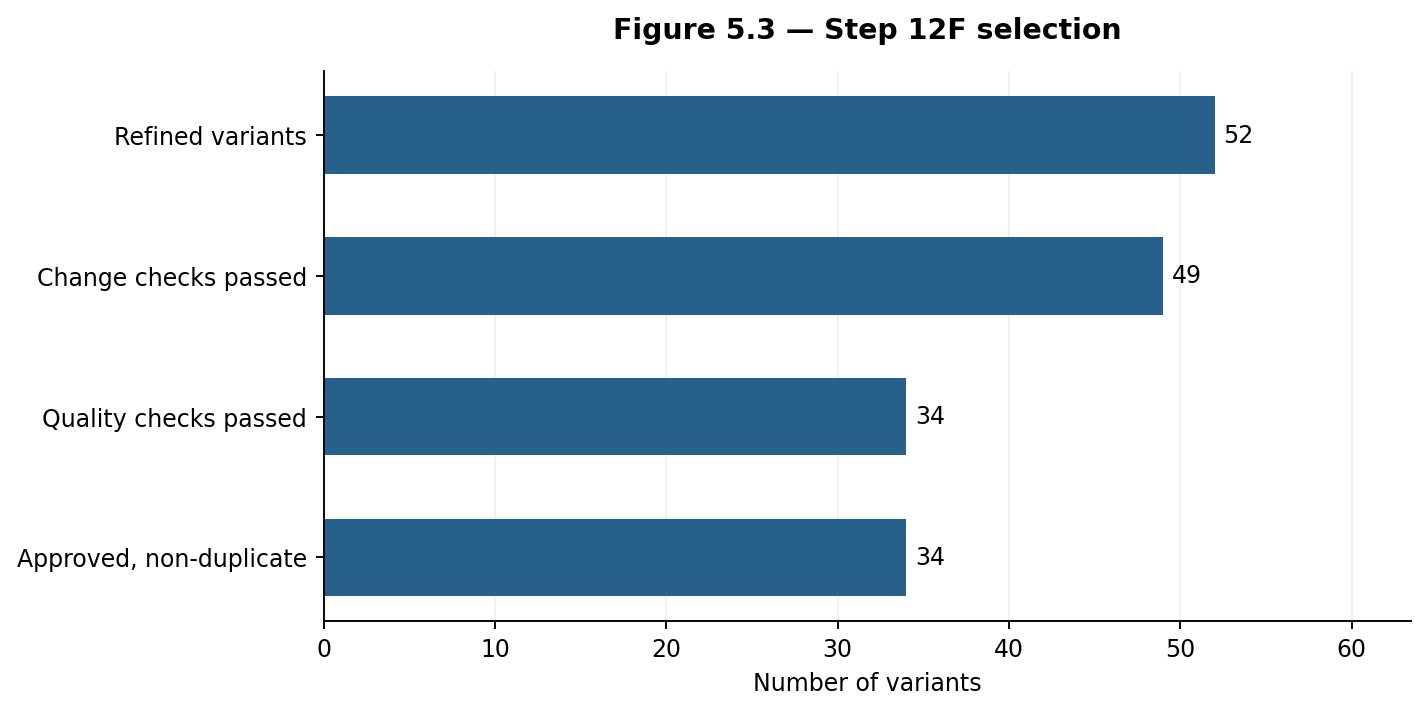

Figure 5.3 shows the selection steps for the refined variants. The checks are related, but they should not be read as four separate groups of emails.

**Table 5.4 — Comparison of the two editing stages**

| Measure | Step 12E | Step 12F |
|:--|--:|--:|
| Generated variants | 52 | 52 |
| Quality checks passed | 34 | 34 |
| Approved, non-duplicate variants | 34 | 34 |
| Baseline predicted legitimate | 30 | 36 |
| Mean TF-IDF cosine similarity | 0.859137 | 0.870464 |

The refined editing method increased the number of variants predicted as legitimate from 30 to 36. This is an observation about the generated emails, **not evidence of improved test-set performance**. Model retraining and false-negative safety checks take place in later notebooks.


## 4. Export the experimental evidence

The exported files record the generated emails, feature changes, quality decisions, and approved variants. They provide a traceable record of the two stages without replacing any figures or tables from the original thesis experiment.

In [ ]:
OUTPUT_DIR = "synthetic_variant_generation_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

synthetic_all_12e.to_csv(
    os.path.join(OUTPUT_DIR, "Step12E_All_Controlled_Synthetic_Emails.csv"), index=False
)
approved_synthetic_12e.to_csv(
    os.path.join(OUTPUT_DIR, "Step12E_Approved_Synthetic_Legitimate_Emails.csv"), index=False
)
synthetic_change_log_12e.to_csv(
    os.path.join(OUTPUT_DIR, "Step12E_Synthetic_Feature_Change_Log.csv"), index=False
)
reserved_templates_12e.to_csv(
    os.path.join(OUTPUT_DIR, "Step12E_Reserved_Unmatched_Templates.csv"), index=False
)

refined_synthetic_df_12f.to_csv(
    os.path.join(OUTPUT_DIR, "Step12F_All_Refined_Synthetic_Emails.csv"), index=False
)
approved_refined_12f.to_csv(
    os.path.join(OUTPUT_DIR, "Step12F_Final_Approved_Synthetic_Legitimate_Emails.csv"), index=False
)
synthetic_training_ready_12f.to_csv(
    os.path.join(OUTPUT_DIR, "Step12F_Training_Ready_Synthetic_Legitimate_Emails.csv"), index=False
)
refined_change_log_12f.to_csv(
    os.path.join(OUTPUT_DIR, "Step12F_Refined_Feature_Change_Log.csv"), index=False
)
reserved_templates_12f.to_csv(
    os.path.join(OUTPUT_DIR, "Step12F_Reserved_Unmatched_Templates.csv"), index=False
)

config = {
    "research_framework": "SHAP-informed explainability-guided refinement",
    "step_12e": {
        "fully_mapped_templates": 52,
        "generated_variants": 52,
        "generation_quality_passes": 34,
        "baseline_predicted_legitimate": 30,
        "approved_nonduplicate": 34,
        "minimum_length_ratio": 0.70,
        "maximum_length_ratio": 1.10,
        "minimum_tfidf_similarity": 0.80,
    },
    "step_12f": {
        "refined_variants": 52,
        "counterfactual_change_passes": 49,
        "generation_quality_passes": 34,
        "approved_nonduplicate": 34,
        "baseline_predicted_legitimate": 36,
        "minimum_tfidf_similarity": 0.85,
        "minimum_length_ratio": 0.80,
        "maximum_length_ratio": 1.08,
        "minimum_token_retention": 0.80,
        "counterfactual_reduction_tolerance": 0.10,
    },
    "model_retrained": False,
    "tfidf_refitted": False,
    "threshold_tuned": False,
    "baseline_coefficients_modified": False,
}

with open(os.path.join(OUTPUT_DIR, "Step12E_12F_Config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

# Convenient objects for 06_fn_safety_screening.ipynb
synthetic_refined_all_12f = refined_synthetic_df_12f.copy()
synthetic_final_approved_12f = synthetic_training_ready_12f.copy()
synthetic_refined_change_log_12f = refined_change_log_12f.copy()

print("Saved reproducibility outputs to:", OUTPUT_DIR)
print("Training-ready approved variants:", len(synthetic_final_approved_12f))

## 5. Findings and conclusion

I started with 56 feasible counterfactual templates and used the 52 that could be fully matched to the original email text. Both editing stages produced 34 approved, non-duplicate variants. The refined method gave more natural replacements for some web-related text and increased the number of variants classified as legitimate by the unchanged model from 30 to 36.

I kept the 34 approved refined emails separate for the next stage, where I will check whether they can be used safely. I did not retrain the model, refit the TF-IDF vectorizer, or change the decision threshold in this notebook.

**Reproducibility note:** The tables and figures above contain recorded results from the original experiment. The code cells have no saved outputs in this version. I need to run the notebook with the original model and mappings to confirm that the same values are produced.
